### Experimentos extras

Este notebook complementa `deterministico.ipynb` e `naodeterministico.ipynb` com cinco experimentos:

1. **Política ótima como referência:** quão perto do melhor possível os agentes chegaram, e se a meta de reward 8 é alcançável.
2. **Decaimento do ε:** o que muda quando o agente explora por mais tempo.
3. **Intensidade da chuva:** desempenho com `rainy_probability` de 0,2 a 1,0.
4. **Estados-armadilha e visitas no treino:** por que a Q-table treinada sem chuva fica presa quando testada com chuva (Item 4).
5. **Expected Sarsa:** um terceiro algoritmo, comparado com Q-learning e Sarsa.

Todos os experimentos usam os mesmos hiperparâmetros dos notebooks principais (α=0,1, γ=0,99, ε de 0,7 a 0,05) e seeds fixas, então o notebook inteiro é reproduzível. Ele leva cerca de 20 minutos para rodar.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from agentes import QLearning, Sarsa, ExpectedSarsa, criar_env, avaliar, avaliar_q_table

os.makedirs('results_experimentos', exist_ok=True)

CHUVA = dict(is_rainy=True, rainy_probability=0.6)
PARAMS = dict(alpha=0.1, gamma=0.99, epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99)
N_RUNS = 5
ACOES = ['Sul', 'Norte', 'Leste', 'Oeste', 'Pegar', 'Deixar']

env_ref = criar_env().unwrapped
# estados que podem aparecer num episódio (passageiro no táxi ou fora do destino)
ESTADOS_VALIDOS = [s for s in range(env_ref.observation_space.n)
                   if (lambda r, c, p, d: p == 4 or p != d)(*env_ref.decode(s))]
P_CHUVA = criar_env(**CHUVA).unwrapped.P


def politica_otima(gamma=0.99, tol=1e-10, **env_kwargs):
    """Q* por iteração de valor, usando o modelo de transições do ambiente (env.P)."""
    P = criar_env(**env_kwargs).unwrapped.P
    nS, nA = len(P), len(P[0])
    K = max(len(P[s][a]) for s in range(nS) for a in range(nA))
    prob, rew, fim = np.zeros((nS, nA, K)), np.zeros((nS, nA, K)), np.zeros((nS, nA, K))
    prox = np.zeros((nS, nA, K), dtype=int)
    for s in range(nS):
        for a in range(nA):
            for k, (p, s2, r, d) in enumerate(P[s][a]):
                prob[s, a, k], prox[s, a, k], rew[s, a, k], fim[s, a, k] = p, s2, r, d
    V = np.zeros(nS)
    while True:
        Q = (prob * (rew + gamma * V[prox] * (1 - fim))).sum(axis=2)
        V_novo = Q.max(axis=1)
        if np.max(np.abs(V_novo - V)) < tol:
            return Q
        V = V_novo


def estados_armadilha(q_table):
    """Estados em que a ação gulosa é um movimento bloqueado por parede ou borda.

    Com chuva, um movimento bloqueado não sofre desvio: o táxi fica parado com
    100% de chance e, sem exploração, repete a mesma ação para sempre.
    """
    P = P_CHUVA
    armadilhas = []
    for s in ESTADOS_VALIDOS:
        a = int(np.argmax(q_table[s]))
        if a < 4 and all(s2 == s for p, s2, r, d in P[s][a] if p > 0):
            armadilhas.append(s)
    return armadilhas


def media_movel(x, window=100):
    return np.convolve(x, np.ones(window) / window, mode='valid')


def primeiro_episodio(rewards, limiar, window=100):
    acima = np.where(media_movel(np.array(rewards), window) >= limiar)[0]
    return int(acima[0] + window) if len(acima) > 0 else np.nan

### 1. Política ótima como referência

O Taxi é pequeno (500 estados) e o Gymnasium expõe o modelo de transições do ambiente (`env.P`). Com ele dá para calcular a política ótima exata por **iteração de valor**, usando o mesmo γ=0,99 dos agentes. Essa política é o melhor resultado possível e serve de régua para os agentes treinados.

In [2]:
q_otima_seca = politica_otima()
q_otima_chuva = politica_otima(**CHUVA)

# média exata da política ótima sem chuva, sobre todos os estados iniciais possíveis
P_seco = env_ref.P
iniciais = np.nonzero(env_ref.initial_state_distrib)[0]
passos_otimos = []
for s in iniciais:
    s, passos, fim = int(s), 0, False
    while not fim:
        _, s, _, fim = P_seco[s][int(np.argmax(q_otima_seca[s]))][0]
        passos += 1
    passos_otimos.append(passos)
passos_otimos = np.array(passos_otimos)

print(f"Estados iniciais possíveis: {len(iniciais)}")
print(f"Política ótima sem chuva: {passos_otimos.mean():.2f} passos em média "
      f"(reward médio {np.mean(21 - passos_otimos):.2f}), de {passos_otimos.min()} a {passos_otimos.max()} passos")

Estados iniciais possíveis: 300
Política ótima sem chuva: 13.07 passos em média (reward médio 7.93), de 6 a 18 passos


In [3]:
N_EVAL_CHUVA = 2000  # com chuva, 100 episódios dão um erro de ~1 passo na média

def resumo(df):
    return df.loc['Média', ['Timesteps (média)', 'Reward médio', 'Não terminou']].to_dict()

linhas = [
    {'Testado em': 'Sem chuva', 'Agente': 'Política ótima',
     **avaliar_q_table(q_otima_seca)},
    {'Testado em': 'Sem chuva', 'Agente': 'Q-learning (treino sem chuva)', **resumo(avaliar('data_qlearning', 'qlearning'))},
    {'Testado em': 'Sem chuva', 'Agente': 'Sarsa (treino sem chuva)', **resumo(avaliar('data_sarsa', 'sarsa'))},
    {'Testado em': 'Com chuva', 'Agente': 'Política ótima',
     **avaliar_q_table(q_otima_chuva, n_eval=N_EVAL_CHUVA, **CHUVA)},
    {'Testado em': 'Com chuva', 'Agente': 'Q-learning (treino com chuva)',
     **resumo(avaliar('data_qlearning_rainy', 'qlearning', n_eval=N_EVAL_CHUVA, **CHUVA))},
    {'Testado em': 'Com chuva', 'Agente': 'Sarsa (treino com chuva)',
     **resumo(avaliar('data_sarsa_rainy', 'sarsa', n_eval=N_EVAL_CHUVA, **CHUVA))},
    {'Testado em': 'Com chuva', 'Agente': 'Q-learning (treino sem chuva)',
     **resumo(avaliar('data_qlearning', 'qlearning', n_eval=N_EVAL_CHUVA, **CHUVA))},
    {'Testado em': 'Com chuva', 'Agente': 'Sarsa (treino sem chuva)',
     **resumo(avaliar('data_sarsa', 'sarsa', n_eval=N_EVAL_CHUVA, **CHUVA))},
]
ref = pd.DataFrame(linhas)[['Testado em', 'Agente', 'Timesteps (média)', 'Reward médio', 'Não terminou']]
ref['Episódios de teste'] = [100] * 3 + [N_EVAL_CHUVA] * 5
ref.round(2)

,Testado em,Agente,Timesteps (média),Reward médio,Não terminou,Episódios de teste
0,Sem chuva,Política ótima,13.31,7.69,0.0,100
1,Sem chuva,Q-learning (treino sem chuva),13.31,7.69,0.0,100
2,Sem chuva,Sarsa (treino sem chuva),13.32,7.68,0.0,100
3,Com chuva,Política ótima,24.85,-3.85,0.0,2000
4,Com chuva,Q-learning (treino com chuva),25.29,-4.29,0.0,2000
5,Com chuva,Sarsa (treino com chuva),25.86,-4.90,4.0,2000
6,Com chuva,Q-learning (treino sem chuva),29.75,-9.23,45.8,2000
7,Com chuva,Sarsa (treino sem chuva),28.97,-8.34,35.4,2000


#### Discussão — política ótima

A coluna "Não terminou" é a média por execução (episódios que passaram de 200 passos).

- **Sem chuva, o Q-learning chegou à política ótima.** Nos 100 episódios de teste dos notebooks, a política ótima faz 13,31 passos (reward 7,69), exatamente o resultado das 5 execuções do Q-learning. O Sarsa ficou a 0,01 passo disso.
- **A meta de 8 é a média da política ótima.** Considerando todos os 300 estados iniciais possíveis, a política ótima faz em média 13,07 passos, ou reward 7,93. Os 100 episódios de teste são um pouco mais longos que a média, por isso nem a política ótima passa de 7,69 neles.
- **Com chuva, a meta é impossível.** Mesmo a política ótima fica com reward médio de −3,85 (24,85 passos). O Q-learning treinado com chuva ficou a 0,44 passo do ótimo e o Sarsa a 1,01 passo.
- **Com 2000 episódios de teste a comparação com chuva fica mais clara.** O Q-learning treinado com chuva nunca ficou preso; o Sarsa ficou preso em 4 de cada 2000 episódios em média, todos nas execuções 2 e 4 (ver experimento 4). As Q-tables treinadas sem chuva ficam presas em cerca de 2% dos episódios (45,8 e 35,4 a cada 2000), o mesmo que o Item 4 mediu com 100 episódios.

### 2. Decaimento do ε

Nos notebooks principais o ε é multiplicado por 0,99 a cada episódio e chega ao mínimo (0,05) já no episódio 264. Aqui o Q-learning sem chuva é treinado com três decaimentos: 0,99 (o original), 0,999 (chega ao mínimo no episódio ~2600) e 0,9995 (~5300).

Além do reward do treino, a cada 250 episódios a política **gulosa** (sem exploração) é testada nos mesmos 100 episódios de teste dos notebooks. Isso separa duas coisas que a curva do treino mistura: o que o agente já sabe (política gulosa) e o quanto ele ainda explora.

In [4]:
DECAIMENTOS = [0.99, 0.999, 0.9995]
A_CADA = 250
EPISODIOS = 10_000
OTIMO_100 = avaliar_q_table(q_otima_seca)['Timesteps (média)']

exp_eps = {}
for dec in DECAIMENTOS:
    gulosa, rewards, epsilons = [], [], None
    for run in range(N_RUNS):
        pontos = []

        def medir(i, ag):
            if i % A_CADA == 0:
                pontos.append(avaliar_q_table(ag.q_table, max_steps=100)['Timesteps (média)'])

        ag = QLearning(criar_env(), episodes=EPISODIOS, seed=run, **{**PARAMS, 'epsilon_dec': dec})
        ag.train(log_every=0, callback=medir)
        gulosa.append(pontos)
        rewards.append(ag.rewards_per_episode)
        epsilons = ag.epsilon_per_episode
    exp_eps[dec] = dict(gulosa=np.array(gulosa), rewards=np.array(rewards), epsilons=np.array(epsilons))

checkpoints = np.arange(A_CADA, EPISODIOS + 1, A_CADA)
linhas = []
for dec, r in exp_eps.items():
    otima = [checkpoints[np.argmax(g <= OTIMO_100 + 1e-9)] if (g <= OTIMO_100 + 1e-9).any() else np.nan for g in r['gulosa']]
    linhas.append({'epsilon_dec': str(dec),
                   'ε chega a 0,05 no episódio': int(np.argmax(r['epsilons'] <= 0.05)) + 1,
                   'Treino: reward ≥ 0 (episódio médio)': np.mean([primeiro_episodio(x, 0) for x in r['rewards']]),
                   'Gulosa ótima pela 1ª vez (episódio médio)': np.mean(otima),
                   'Treino: reward médio (últimos 1000 ep.)': r['rewards'][:, -1000:].mean()})
pd.DataFrame(linhas).round(2)

,epsilon_dec,"ε chega a 0,05 no episódio",Treino: reward ≥ 0 (episódio médio),Gulosa ótima pela 1ª vez (episódio médio),Treino: reward médio (últimos 1000 ep.)
0,0.99,264,949.6,3150.0,5.17
1,0.999,2639,1699.0,3400.0,5.31
2,0.9995,5278,3172.8,3000.0,5.23


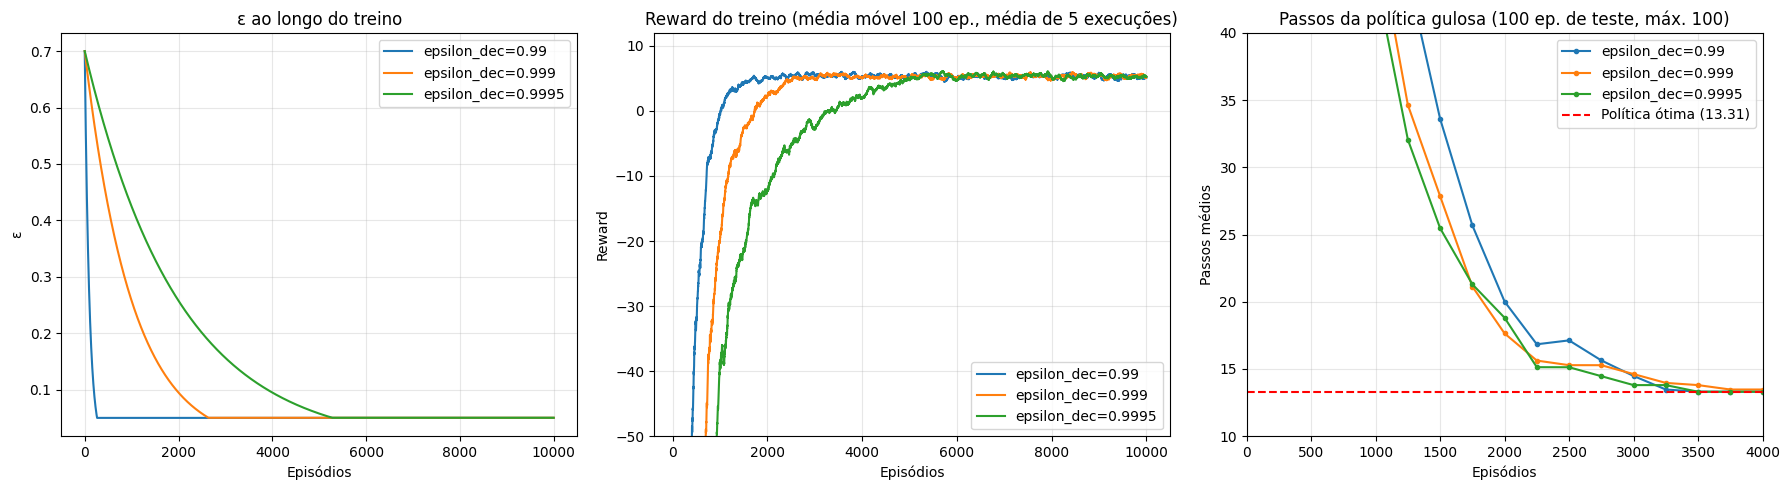

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for dec, r in exp_eps.items():
    axes[0].plot(r['epsilons'], label=f'epsilon_dec={dec}')
    sm = np.array([media_movel(x) for x in r['rewards']]).mean(axis=0)
    axes[1].plot(np.arange(len(sm)) + 100, sm, label=f'epsilon_dec={dec}')
    axes[2].plot(checkpoints, r['gulosa'].mean(axis=0), marker='o', markersize=3, label=f'epsilon_dec={dec}')

axes[0].set(title='ε ao longo do treino', xlabel='Episódios', ylabel='ε')
axes[1].set(title='Reward do treino (média móvel 100 ep., média de 5 execuções)', xlabel='Episódios',
            ylabel='Reward', ylim=(-50, 12))
axes[2].axhline(OTIMO_100, color='red', linestyle='--', label=f'Política ótima ({OTIMO_100:.2f})')
axes[2].set(title='Passos da política gulosa (100 ep. de teste, máx. 100)', xlabel='Episódios',
            ylabel='Passos médios', ylim=(10, 40), xlim=(0, 4000))
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig('results_experimentos/decaimento_epsilon.jpg', dpi=120)
plt.show()

#### Discussão — decaimento do ε

| epsilon_dec | ε chega a 0,05 no episódio | Treino: reward ≥ 0 | Política gulosa ótima pela 1ª vez | Treino: reward final |
|---|---|---|---|---|
| 0,99 (original) | 264 | 950 | 3150 | 5,17 |
| 0,999 | 2639 | 1699 | 3400 | 5,31 |
| 0,9995 | 5278 | 3173 | 3000 | 5,23 |

- **A curva do treino engana.** Com mais exploração, o reward do treino demora muito mais para subir (reward ≥ 0 no episódio 950 com 0,99, mas só no 3173 com 0,9995). Só que o gráfico da direita mostra que a política gulosa, ou seja, o que o agente realmente aprendeu, melhora quase no mesmo ritmo nos três casos, e até um pouco mais rápido com mais exploração até o episódio ~2000 (no episódio 1500: 33,6 passos com 0,99 contra 25,5 com 0,9995). O reward do treino fica baixo só porque o agente está escolhendo muitas ações aleatórias.
- **O aprendizado termina depois do que a curva do treino sugere.** Com o decaimento original, o reward do treino estabiliza por volta do episódio 2000, mas a política gulosa só fica ótima nos 100 episódios de teste por volta do episódio 3000 (média das 5 execuções, medindo a cada 250 episódios).
- **No fim, os três chegam ao mesmo lugar.** Depois que o ε chega ao mínimo, o reward do treino fica igual (5,2 a 5,3) e a política gulosa é a ótima.

**Conclusão:** no Taxi, o ritmo de decaimento do ε quase não muda o que o agente aprende; ele muda principalmente a curva de reward do treino. Para comparar algoritmos, testar a política gulosa é mais confiável do que olhar só o reward do treino.

### 3. Intensidade da chuva

`rainy_probability` é a chance do táxi ir para onde quer; o resto se divide igualmente entre os dois lados. Aqui Q-learning e Sarsa são treinados (20.000 episódios, 3 execuções cada) com chuva de 0,2 a 1,0, e comparados com a política ótima de cada caso. Com 1,0 o táxi nunca desvia, então é igual ao ambiente sem chuva.

Como com chuva forte os episódios ficam longos, o teste usa 1000 episódios com limite de 1000 passos.

In [6]:
PROBS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_RUNS_CHUVA = 3

linhas = []
for p in PROBS:
    kw = dict(is_rainy=True, rainy_probability=p)
    linhas.append({'rainy_probability': p, 'Agente': 'Política ótima', 'Execução': 1,
                   **avaliar_q_table(politica_otima(**kw), n_eval=1000, max_steps=1000, **kw),
                   'Estados-armadilha': 0})
    for nome, cls in [('Q-learning', QLearning), ('Sarsa', Sarsa)]:
        for run in range(N_RUNS_CHUVA):
            ag = cls(criar_env(**kw), episodes=20_000, seed=run, **PARAMS)
            ag.train(log_every=0)
            linhas.append({'rainy_probability': p, 'Agente': nome, 'Execução': run + 1,
                           **avaliar_q_table(ag.q_table, n_eval=1000, max_steps=1000, **kw),
                           'Estados-armadilha': len(estados_armadilha(ag.q_table))})

chuva = pd.DataFrame(linhas)
tabela_chuva = (chuva.groupby(['rainy_probability', 'Agente'])
                     .agg({'Timesteps (média)': 'mean', 'Reward médio': 'mean',
                           'Não terminou': 'sum', 'Estados-armadilha': 'sum'})
                     .round(2))
tabela_chuva

Timesteps (média)  Reward médio  \
rainy_probability Agente                                            
0.2               Política ótima              70.17        -49.17   
                  Q-learning                 184.95       -166.49   
                  Sarsa                      153.14       -133.87   
0.4               Política ótima              46.60        -25.60   
                  Q-learning                  56.16        -35.32   
                  Sarsa                       93.97        -73.97   
0.6               Política ótima              25.24         -4.24   
                  Q-learning                  25.58         -4.58   
                  Sarsa                       28.35         -7.40   
0.8               Política ótima              17.25          3.75   
                  Q-learning                  17.50          3.50   
                  Sarsa                       17.61          3.39   
1.0               Política ótima              13.13          7.87   
                  Q-learning                  13.13          7.87   
                  Sarsa                       13.14          7.86   

                                  Não terminou  Estados-armadilha  
rainy_probability Agente                                           
0.2               Política ótima           0.0                  0  
                  Q-learning             363.0                 11  
                  Sarsa                  248.0                 11  
0.4               Política ótima           0.0                  0  
                  Q-learning              23.0                  2  
                  Sarsa                  143.0                 11  
0.6               Política ótima           0.0                  0  
                  Q-learning               0.0                  0  
                  Sarsa                    8.0                  1  
0.8               Política ótima           0.0                  0  
                  Q-learning               0.0                  0  
                  Sarsa                    0.0                  0  
1.0               Política ótima           0.0                  0  
                  Q-learning               0.0                 13  
                  Sarsa                    0.0                 10

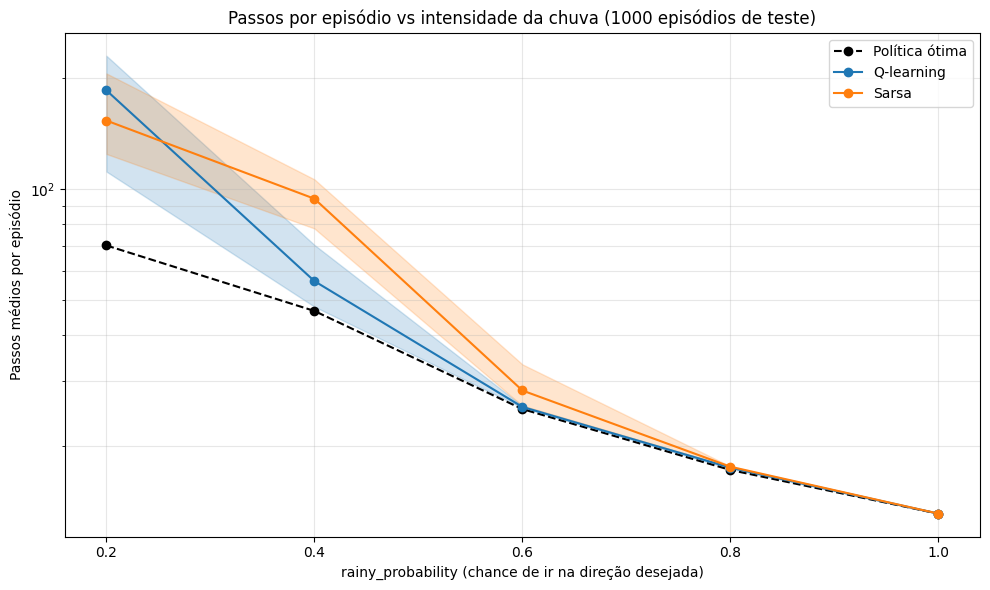

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
for nome, cor in [('Política ótima', 'black'), ('Q-learning', 'tab:blue'), ('Sarsa', 'tab:orange')]:
    d = chuva[chuva['Agente'] == nome].groupby('rainy_probability')['Timesteps (média)']
    ax.plot(PROBS, d.mean(), marker='o', color=cor, label=nome,
            linestyle='--' if nome == 'Política ótima' else '-')
    if nome != 'Política ótima':
        ax.fill_between(PROBS, d.min(), d.max(), color=cor, alpha=0.2)
ax.set(xlabel='rainy_probability (chance de ir na direção desejada)', ylabel='Passos médios por episódio',
       title='Passos por episódio vs intensidade da chuva (1000 episódios de teste)', yscale='log')
ax.set_xticks(PROBS)
ax.grid(True, alpha=0.3, which='both')
ax.legend()
plt.tight_layout()
plt.savefig('results_experimentos/intensidade_chuva.jpg', dpi=120)
plt.show()

#### Discussão — intensidade da chuva

"Não terminou" é o total nos 3000 episódios de teste (3 execuções × 1000) e "Estados-armadilha" é o total nas 3 Q-tables (ver experimento 4).

| rainy_probability | Passos: ótima | Passos: Q-learning | Passos: Sarsa | Não terminou: Q-learning | Não terminou: Sarsa |
|---|---|---|---|---|---|
| 0,2 | 70,17 | 184,95 | 153,14 | 363 | 248 |
| 0,4 | 46,60 | 56,16 | 93,97 | 23 | 143 |
| 0,6 | 25,24 | 25,58 | 28,35 | 0 | 8 |
| 0,8 | 17,25 | 17,50 | 17,61 | 0 | 0 |
| 1,0 | 13,13 | 13,13 | 13,14 | 0 | 0 |

- **O custo da chuva cresce rápido.** Mesmo a política ótima vai de 13 passos sem desvio para 25 com 0,6 e 70 com 0,2. A meta de reward 8 só é alcançável sem desvio (reward ótimo de 3,75 já com 0,8).
- **Com chuva até 0,6, os agentes ficam perto do ótimo.** O Q-learning fica a no máximo 0,34 passo da política ótima entre 0,6 e 1,0.
- **Com chuva forte (0,4 e 0,2), 20.000 episódios não bastam.** Os dois algoritmos ficam longe do ótimo e muitos episódios não terminam. Com 0,4 o Sarsa foi bem pior que o Q-learning (94 contra 56 passos, 11 estados-armadilha contra 2), o mesmo padrão do experimento 5: com chuva, o Q-learning termina o treino com menos armadilhas.
- **Armadilhas só fazem mal se o táxi chegar nelas.** Sem desvio (1,0), as Q-tables têm 13 e 10 estados-armadilha e mesmo assim nunca ficam presas, porque o táxi sempre segue o caminho aprendido e nunca passa por esses estados. É o mesmo fenômeno do Item 4, visto pelo outro lado.

### 4. Estados-armadilha e visitas no treino (Item 4)

No Item 4 do notebook não determinístico, a Q-table treinada sem chuva às vezes fica presa quando é testada com chuva. A explicação proposta foi: a chuva empurra o táxi para estados pouco visitados no treino, onde a Q-table escolhe andar contra a parede.

Aqui isso é medido diretamente. Um **estado-armadilha** é um estado em que a ação gulosa é um movimento bloqueado por parede ou borda. Com chuva, um movimento bloqueado não sofre desvio: o táxi fica parado com 100% de chance e repete a ação para sempre.

Os agentes dos notebooks principais são re-treinados com as mesmas seeds (o que gera exatamente as mesmas Q-tables) para recuperar quantas vezes cada estado foi visitado no treino.

In [8]:
agentes = {}
historico = {}
for treino, kw, episodios, pastas in [
        ('Sem chuva', {}, 10_000, {'Q-learning': ('data_qlearning', 'qlearning'), 'Sarsa': ('data_sarsa', 'sarsa')}),
        ('Com chuva', CHUVA, 20_000, {'Q-learning': ('data_qlearning_rainy', 'qlearning'), 'Sarsa': ('data_sarsa_rainy', 'sarsa')})]:
    for nome, cls in [('Q-learning', QLearning), ('Sarsa', Sarsa)]:
        for run in range(N_RUNS):
            snapshots = []

            def guardar(i, ag):
                # Q-table a cada 50 episódios, nos últimos 5000 episódios do treino
                if i > episodios - 5000 and i % 50 == 0:
                    snapshots.append(ag.q_table.copy())

            ag = cls(criar_env(**kw), episodes=episodios, seed=run, **PARAMS)
            ag.train(log_every=0, callback=guardar)
            pasta, prefixo = pastas[nome]
            salva = np.loadtxt(f'{pasta}/q-table-taxi-driver-{prefixo}-run{run+1}.csv', delimiter=',')
            assert np.array_equal(ag.q_table, salva), 'Q-table diferente da salva pelo notebook'
            agentes[(treino, nome, run)] = ag
            historico[(treino, nome, run)] = np.array(snapshots)

print('As 20 Q-tables re-treinadas são idênticas às salvas pelos notebooks principais.')

armadilhas = pd.DataFrame(
    {f'Execução {run+1}': [len(estados_armadilha(agentes[(t, n, run)].q_table))
                           for t in ['Sem chuva', 'Com chuva'] for n in ['Q-learning', 'Sarsa']]
     for run in range(N_RUNS)},
    index=pd.MultiIndex.from_product([['Sem chuva', 'Com chuva'], ['Q-learning', 'Sarsa']],
                                     names=['Treinado', 'Algoritmo']))
armadilhas['Total'] = armadilhas.sum(axis=1)
armadilhas

As 20 Q-tables re-treinadas são idênticas às salvas pelos notebooks principais.


Execução 1  Execução 2  Execução 3  Execução 4  \
Treinado  Algoritmo                                                    
Sem chuva Q-learning           2           5           6           2   
          Sarsa                2           5           4           4   
Com chuva Q-learning           0           0           0           0   
          Sarsa                0           1           0           1   

                      Execução 5  Total  
Treinado  Algoritmo                      
Sem chuva Q-learning           5     20  
          Sarsa                2     17  
Com chuva Q-learning           0      0  
          Sarsa                0      2

In [9]:
def descrever(s):
    linha, coluna, passageiro, destino = env_ref.decode(s)
    return (linha, coluna), 'no táxi' if passageiro == 4 else 'RGYB'[passageiro], 'RGYB'[destino]

linhas = []
for (treino, nome, run), ag in agentes.items():
    visitas = ag.visits.sum(axis=1)[ESTADOS_VALIDOS]
    for s in estados_armadilha(ag.q_table):
        taxi, passageiro, destino = descrever(s)
        linhas.append({'Treinado': treino, 'Algoritmo': nome, 'Execução': run + 1, 'Estado': s,
                       'Táxi (linha, coluna)': taxi, 'Passageiro': passageiro, 'Destino': destino,
                       'Ação gulosa': ACOES[int(np.argmax(ag.q_table[s]))],
                       'Visitas no treino': int(ag.visits[s].sum()),
                       'Percentil das visitas': round(float((visitas < ag.visits[s].sum()).mean() * 100), 1),
                       'Maior Q do estado': round(float(ag.q_table[s].max()), 2)})
estados_presos = pd.DataFrame(linhas)

visitas_secas = np.concatenate([agentes[('Sem chuva', n, r)].visits.sum(axis=1)[ESTADOS_VALIDOS]
                                for n in ['Q-learning', 'Sarsa'] for r in range(N_RUNS)])
print(f"Treino sem chuva: mediana de {np.median(visitas_secas):.0f} visitas por estado")
estados_presos

Treino sem chuva: mediana de 369 visitas por estado


,Treinado,Algoritmo,Execução,Estado,"Táxi (linha, coluna)",Passageiro,Destino,Ação gulosa,Visitas no treino,Percentil das visitas,Maior Q do estado
0,Sem chuva,Q-learning,1,457,"(4, 2)",no táxi,G,Leste,72,5.0,-1.48
1,Sem chuva,Q-learning,1,458,"(4, 2)",no táxi,Y,Leste,67,4.0,-1.14
2,Sem chuva,Q-learning,2,437,"(4, 1)",no táxi,G,Oeste,68,4.2,-1.37
3,Sem chuva,Q-learning,2,439,"(4, 1)",no táxi,B,Oeste,71,5.0,-1.18
4,Sem chuva,Q-learning,2,456,"(4, 2)",no táxi,R,Leste,58,2.8,-1.14
5,Sem chuva,Q-learning,2,458,"(4, 2)",no táxi,Y,Leste,57,2.2,-1.06
6,Sem chuva,Q-learning,2,459,"(4, 2)",no táxi,B,Sul,65,3.2,-1.18
7,Sem chuva,Q-learning,3,59,"(0, 2)",no táxi,B,Norte,33,0.8,-0.69
8,Sem chuva,Q-learning,3,437,"(4, 1)",no táxi,G,Oeste,73,5.2,-1.39
9,Sem chuva,Q-learning,3,438,"(4, 1)",no táxi,Y,Sul,68,4.8,-1.45


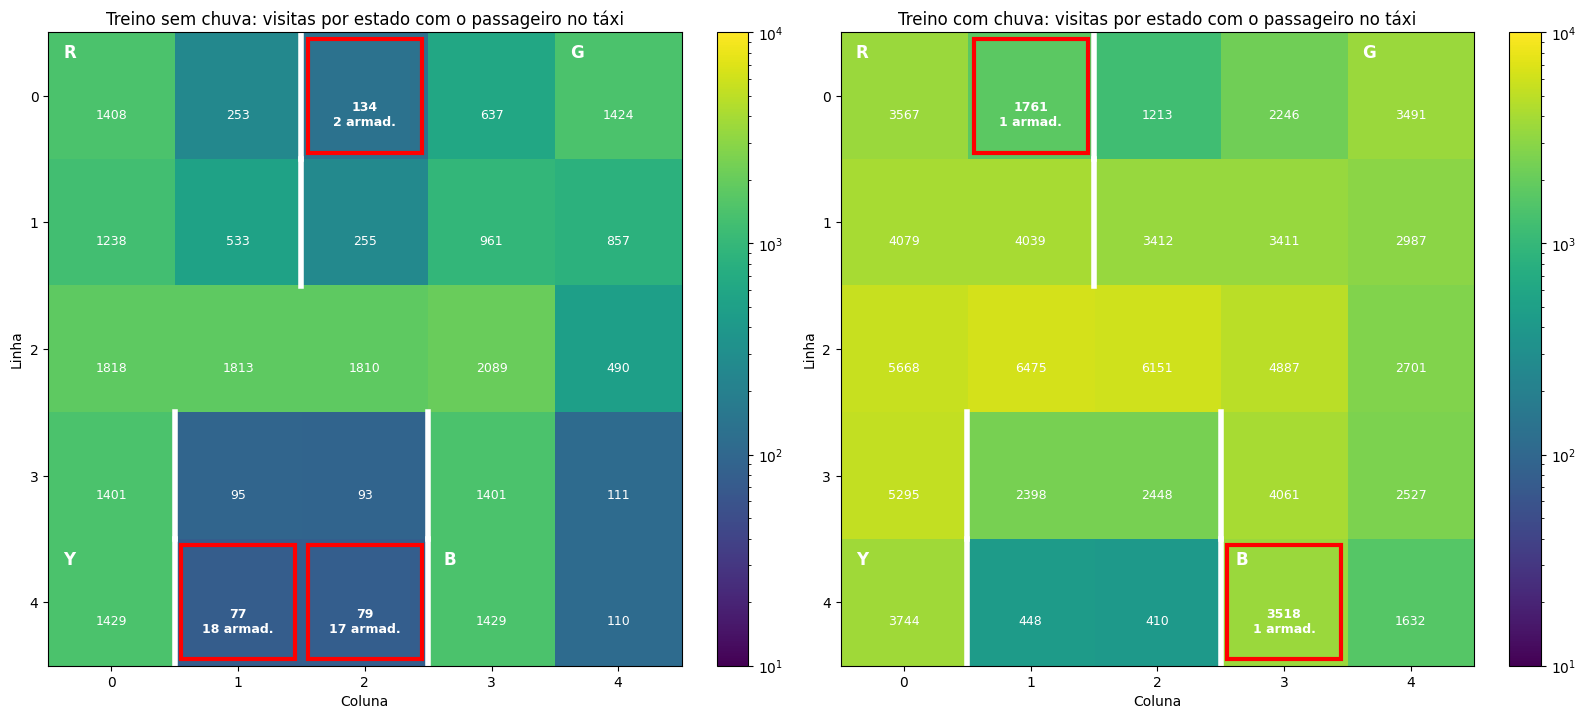

In [10]:
def desenhar_paredes(ax):
    desc = env_ref.desc
    for linha in range(5):
        for coluna in range(4):
            if desc[1 + linha, 2 * coluna + 2] == b'|':
                ax.plot([coluna + 0.5, coluna + 0.5], [linha - 0.5, linha + 0.5], color='white', linewidth=4)
    for (linha, coluna), letra in zip(env_ref.locs, 'RGYB'):
        ax.text(coluna - 0.38, linha - 0.3, letra, color='white', fontsize=12, fontweight='bold')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, treino in zip(axes, ['Sem chuva', 'Com chuva']):
    visitas = np.mean([agentes[(treino, n, r)].visits.sum(axis=1)
                       for n in ['Q-learning', 'Sarsa'] for r in range(N_RUNS)], axis=0)
    grade = np.array([[np.mean([visitas[env_ref.encode(l, c, 4, d)] for d in range(4)]) for c in range(5)]
                      for l in range(5)])
    contagem = np.zeros((5, 5), dtype=int)
    for n in ['Q-learning', 'Sarsa']:
        for r in range(N_RUNS):
            for s in estados_armadilha(agentes[(treino, n, r)].q_table):
                l, c, _, _ = env_ref.decode(s)
                contagem[l, c] += 1
    im = ax.imshow(grade, cmap='viridis', norm=LogNorm(vmin=10, vmax=10_000))
    for l in range(5):
        for c in range(5):
            texto = f'{grade[l, c]:.0f}' + (f'\n{contagem[l, c]} armad.' if contagem[l, c] else '')
            ax.text(c, l + 0.15, texto, ha='center', va='center', fontsize=9, color='white',
                    fontweight='bold' if contagem[l, c] else None)
            if contagem[l, c]:
                ax.add_patch(plt.Rectangle((c - 0.45, l - 0.45), 0.9, 0.9, fill=False, edgecolor='red', linewidth=3))
    desenhar_paredes(ax)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set(title=f'Treino {treino.lower()}: visitas por estado com o passageiro no táxi',
           xlabel='Coluna', ylabel='Linha')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig('results_experimentos/mapa_visitas_armadilhas.jpg', dpi=120)
plt.show()

#### Discussão — armadilhas do treino sem chuva

A tabela de armadilhas confirma a explicação do Item 4:

- **Toda Q-table treinada sem chuva tem armadilhas** (de 2 a 6 por execução, 37 no total). Das treinadas com chuva, o Q-learning não tem nenhuma e o Sarsa tem 1 em duas das cinco execuções.
- **Elas ficam num lugar específico.** Das 37 armadilhas do treino sem chuva, 35 estão nas casas (4,1) e (4,2), o "bolso" no fundo do mapa entre as paredes de Y e B, e 2 na casa (0,2). Em todas o passageiro já está no táxi, e a ação gulosa é andar contra uma parede ou contra a borda do mapa.
- **São estados pouco visitados.** Eles tiveram entre 33 e 113 visitas no treino, contra uma mediana de 369 visitas por estado; todos estão abaixo do percentil 7. O maior Q desses estados ficou entre −0,7 e −3,3, enquanto pela política ótima eles valem entre +11,9 e +14,1 (o táxi está com o passageiro e a poucos passos da entrega). Ou seja, o agente nunca aprendeu o que fazer ali.
- **O mapa de calor mostra por quê.** Sem chuva, o caminho com o passageiro no táxi nunca passa pelo bolso entre Y e B, então essas casas quase não são visitadas (77 e 79 visitas em média). Com chuva, o táxi é empurrado para lá com frequência (448 e 410 visitas) e a Q-table aprende a sair.

In [11]:
linhas = []
for (treino, nome, run), ag in agentes.items():
    if treino != 'Com chuva':
        continue
    for s in estados_armadilha(ag.q_table):
        q = ag.q_table[s, :4]
        acao = int(np.argmax(q))
        hist = historico[(treino, nome, run)][:, s, :4]
        linhas.append({'Algoritmo': nome, 'Execução': run + 1, 'Estado': s,
                       'Táxi (linha, coluna)': descrever(s)[0], 'Ação gulosa (bloqueada)': ACOES[acao],
                       'Q das 4 direções': np.round(q, 2).tolist(),
                       'Diferença para a 2ª melhor': round(float(np.sort(q)[-1] - np.sort(q)[-2]), 3),
                       '% dos últimos 5000 ep. em que era a gulosa': round(float((hist.argmax(axis=1) == acao).mean() * 100), 1)})
pd.DataFrame(linhas)

,Algoritmo,Execução,Estado,"Táxi (linha, coluna)",Ação gulosa (bloqueada),Q das 4 direções,Diferença para a 2ª melhor,% dos últimos 5000 ep. em que era a gulosa
0,Sarsa,2,469,"(4, 3)",Oeste,"[-22.3, -22.22, -22.21, -22.21]",0.001,13.0
1,Sarsa,4,26,"(0, 1)",Norte,"[-21.89, -21.71, -21.81, -21.86]",0.095,12.0


#### Discussão — as duas armadilhas do Sarsa treinado com chuva

As duas armadilhas do Sarsa treinado com chuva têm outra causa. Esses estados foram visitados normalmente (971 e 952 vezes) e o seu Q está bem aprendido (cerca de −22, o que bate com a distância até a entrega). O problema é que neles as quatro direções valem quase o mesmo: a ação bloqueada ficou na frente da segunda melhor por só 0,001 e 0,095.

Com α constante (0,1) e a chuva, os valores da Q-table nunca param de oscilar um pouco. Nos últimos 5000 episódios do treino, a ação bloqueada foi a gulosa em só 13% e 12% do tempo; o treino simplesmente terminou num momento em que ela estava na frente. Durante o treino isso não trava o táxi, porque os 5% de ações aleatórias tiram ele do lugar e cada repetição da ação bloqueada reduz o seu valor. Já na avaliação, sem exploração, o táxi repete a ação para sempre.

Duas formas de evitar isso, que não testamos aqui: diminuir o α ao longo do treino, para os valores pararem de oscilar, ou usar na avaliação o `action_mask` que o Taxi devolve em `info`, que diz quais ações mudam o estado.

### 5. Expected Sarsa

O Expected Sarsa fica no meio do caminho entre os dois algoritmos do projeto. No alvo da atualização, em vez de usar a melhor ação seguinte (Q-learning) ou a ação seguinte sorteada (Sarsa), ele usa a **média** dos valores do próximo estado, ponderada pela probabilidade de cada ação na política ε-greedy:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[r + \gamma \sum_{a'} \pi(a'|s')\, Q(s',a') - Q(s,a)\Big]$$

Assim ele continua on-policy como o Sarsa, mas sem o ruído de sortear a próxima ação. A implementação está em `agentes.py`. Ele é treinado aqui com os mesmos parâmetros, episódios e seeds dos outros dois.

In [12]:
resultados = []
curvas = {}
for treino, kw, episodios, limiares, pastas in [
        ('Sem chuva', {}, 10_000, (0, 4), {'Q-learning': ('data_qlearning', 'qlearning', 'results_qlearning/rewards_qlearning.npy'),
                                            'Sarsa': ('data_sarsa', 'sarsa', 'results_sarsa/rewards_sarsa.npy')}),
        ('Com chuva', CHUVA, 20_000, (-20, -12), {'Q-learning': ('data_qlearning_rainy', 'qlearning', 'results_qlearning_rainy/rewards_qlearning.npy'),
                                                  'Sarsa': ('data_sarsa_rainy', 'sarsa', 'results_sarsa_rainy/rewards_sarsa.npy')})]:
    n_eval = 100 if treino == 'Sem chuva' else N_EVAL_CHUVA
    rewards = {}
    q_tables = {}
    for nome, (pasta, prefixo, arquivo) in pastas.items():
        rewards[nome] = np.load(arquivo)
        q_tables[nome] = [np.loadtxt(f'{pasta}/q-table-taxi-driver-{prefixo}-run{run+1}.csv', delimiter=',')
                          for run in range(N_RUNS)]
    es = [ExpectedSarsa(criar_env(**kw), episodes=episodios, seed=run, **PARAMS) for run in range(N_RUNS)]
    for ag in es:
        ag.train(log_every=0)
    rewards['Expected Sarsa'] = np.array([ag.rewards_per_episode for ag in es])
    q_tables['Expected Sarsa'] = [ag.q_table for ag in es]
    curvas[treino] = rewards

    for nome in ['Q-learning', 'Sarsa', 'Expected Sarsa']:
        testes = pd.DataFrame([avaliar_q_table(q, n_eval=n_eval, **kw) for q in q_tables[nome]])
        resultados.append({'Ambiente': treino, 'Algoritmo': nome,
                           f'Reward ≥ limiar baixo (episódio médio)': np.mean([primeiro_episodio(r, limiares[0]) for r in rewards[nome]]),
                           f'Reward ≥ limiar alto (episódio médio)': np.mean([primeiro_episodio(r, limiares[1]) for r in rewards[nome]]),
                           'Timesteps (média)': testes['Timesteps (média)'].mean(),
                           'Reward médio': testes['Reward médio'].mean(),
                           'Não terminou (total)': testes['Não terminou'].sum(),
                           'Estados-armadilha (total)': sum(len(estados_armadilha(q)) for q in q_tables[nome]),
                           'Episódios de teste': n_eval})
pd.DataFrame(resultados).round(2)

,Ambiente,Algoritmo,Reward ≥ limiar baixo (episódio médio),Reward ≥ limiar alto (episódio médio),Timesteps (média),Reward médio,Não terminou (total),Estados-armadilha (total),Episódios de teste
0,Sem chuva,Q-learning,949.6,1314.8,13.31,7.69,0.0,20,100
1,Sem chuva,Sarsa,1166.8,1446.8,13.32,7.68,0.0,17,100
2,Sem chuva,Expected Sarsa,1080.2,1451.8,13.31,7.69,0.0,26,100
3,Com chuva,Q-learning,1476.4,2136.2,25.29,-4.29,0.0,0,2000
4,Com chuva,Sarsa,1671.6,2626.2,25.86,-4.90,20.0,2,2000
5,Com chuva,Expected Sarsa,1679.8,2411.8,25.41,-4.43,11.0,1,2000


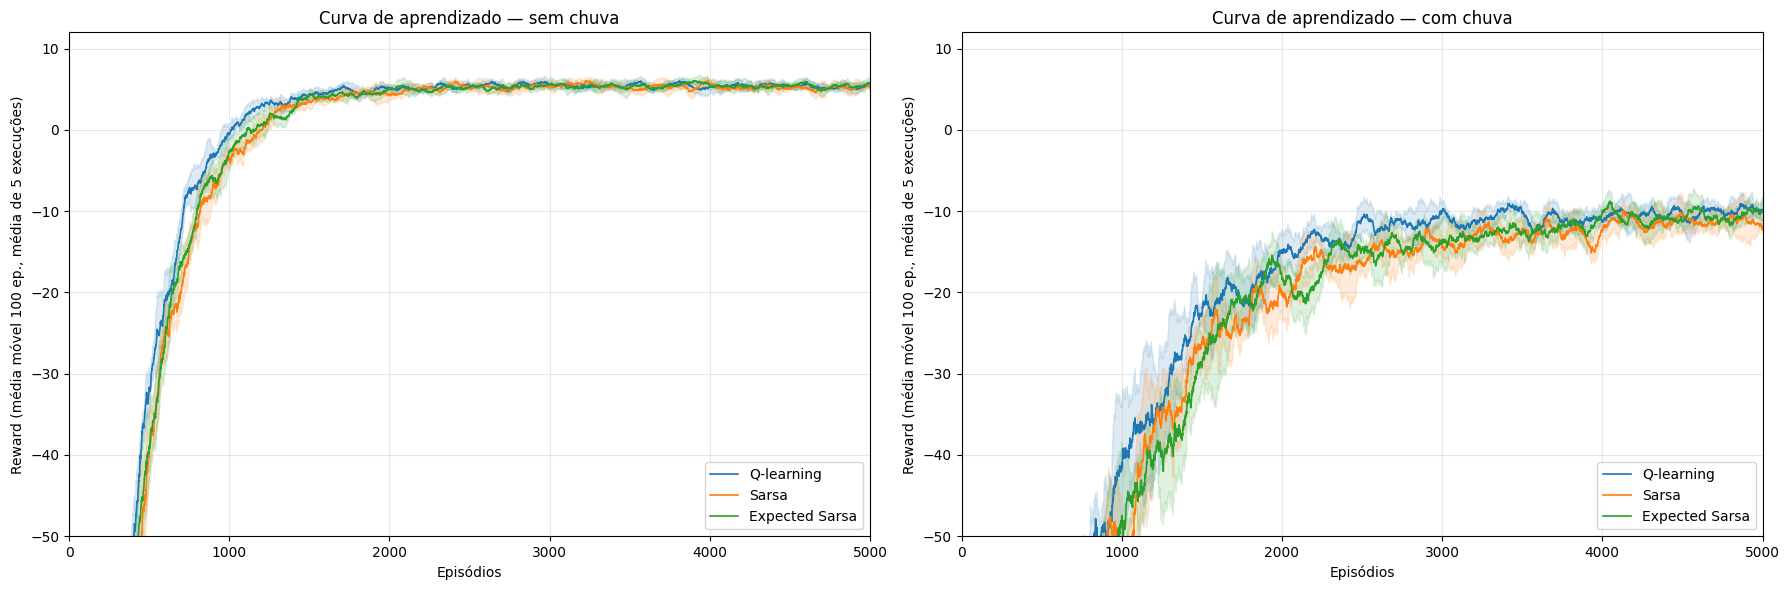

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
cores = {'Q-learning': 'tab:blue', 'Sarsa': 'tab:orange', 'Expected Sarsa': 'tab:green'}
for ax, (treino, rewards) in zip(axes, curvas.items()):
    for nome, r in rewards.items():
        curvas_mm = np.array([media_movel(x) for x in r])
        media, desvio = curvas_mm.mean(axis=0), curvas_mm.std(axis=0)
        x = np.arange(len(media)) + 100
        ax.plot(x, media, color=cores[nome], linewidth=1.2, label=nome)
        ax.fill_between(x, media - desvio, media + desvio, color=cores[nome], alpha=0.15)
    ax.set(title=f'Curva de aprendizado — {treino.lower()}', xlabel='Episódios',
           ylabel='Reward (média móvel 100 ep., média de 5 execuções)', ylim=(-50, 12), xlim=(0, 5000))
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('results_experimentos/expected_sarsa.jpg', dpi=120)
plt.show()

#### Discussão — Expected Sarsa

Os limiares são 0 e 4 sem chuva e −20 e −12 com chuva, iguais aos dos notebooks principais. Sem chuva, o teste usa os 100 episódios dos notebooks; com chuva, 2000 episódios.

| Ambiente | Algoritmo | Limiar baixo | Limiar alto | Passos | Reward médio | Não terminou (total) |
|---|---|---|---|---|---|---|
| Sem chuva | Q-learning | 950 | 1315 | 13,31 | 7,69 | 0 |
| Sem chuva | Sarsa | 1167 | 1447 | 13,32 | 7,68 | 0 |
| Sem chuva | Expected Sarsa | 1080 | 1452 | 13,31 | 7,69 | 0 |
| Com chuva | Q-learning | 1476 | 2136 | 25,29 | −4,29 | 0 |
| Com chuva | Sarsa | 1672 | 2626 | 25,86 | −4,90 | 20 |
| Com chuva | Expected Sarsa | 1680 | 2412 | 25,41 | −4,43 | 11 |

- **Velocidade:** o Expected Sarsa ficou entre os dois. Sem chuva, chegou a reward 0 no episódio 1080, entre o Q-learning (950) e o Sarsa (1167). Com chuva, chegou a −12 no 2412, também entre os dois (2136 e 2626). Ao trocar a ação sorteada pela média, ele tira parte do ruído do alvo do Sarsa, mas continua contando as ações aleatórias, o que o deixa mais lento que o Q-learning.
- **Resultado final:** sem chuva, as 5 execuções chegaram à política ótima (13,31 passos), igual ao Q-learning. Com chuva, ficou com 25,41 passos, entre o Q-learning (25,29) e o Sarsa (25,86).
- **Armadilhas com chuva:** uma execução do Expected Sarsa terminou com 1 estado-armadilha (11 episódios presos em 2000). Somando com o experimento 3, os métodos on-policy (Sarsa e Expected Sarsa) terminaram o treino com chuva com armadilhas mais vezes que o Q-learning. Com poucas execuções não dá para afirmar que isso é uma propriedade dos algoritmos, e não investigamos o motivo.

No Taxi, o Q-learning continua sendo a melhor escolha: foi o mais rápido e o mais próximo do ótimo nos dois ambientes.

### Conclusões dos experimentos extras

1. **O Q-learning chegou à política ótima sem chuva** e, com chuva, ficou a 0,44 passo dela. A meta de reward 8 é a média da política ótima sem chuva (7,93); com chuva ela é impossível, já que o ótimo fica em −3,85.
2. **O decaimento do ε muda a curva de reward do treino, mas quase não muda o que o agente aprende.** Testar a política gulosa mede o aprendizado melhor que o reward do treino.
3. **Quanto mais forte a chuva, mais longe do ótimo ficam os agentes** com o mesmo treino. Até 0,6 eles ficam perto do ótimo; com 0,4 ou menos, 20.000 episódios não bastam.
4. **A explicação do Item 4 está confirmada:** as Q-tables treinadas sem chuva têm "estados-armadilha" (andar contra a parede) concentrados no bolso entre Y e B, estados quase nunca visitados sem chuva. A chuva leva o táxi até eles e, como um movimento bloqueado não sofre desvio, o táxi fica preso.
5. **O Expected Sarsa ficou entre o Q-learning e o Sarsa** em velocidade e em desempenho final.